# Этап 2 (папка 1711) · 01. Эпизоды на свободе и признаки из графа заключений


**Постановка.** Повторное событие — **вход в заключение**, то есть следующий узел графа этапа 1 (переход free → заключение, как в прошлой работе free → jail). Вариант с арестом как событием — в папке `этап2_выбор_события`; здесь аресты используются только как признаки и для определения причины возврата.

**Что делаем.** Для каждого выхода из заключения собираем строку: время до следующего входа в заключение, его причину (новое / старое дело) и признаки, посчитанные **только по истории до момента выхода**.

**Порядок ноутбуков.** 01 (этот) собирает таблицу `out/free_episodes_features.csv` → 02 строит основные модели → 03 проверяет дополнения к модели из 02. Каждый следующий ноутбук читает только то, что записал предыдущий. Признаки разбиты на семейства: от прежних RFM до признаков, которые даёт граф этапа 1. В ноутбуке 02 семейства добавляются по очереди, чтобы было видно, что даёт каждое.

## Как это можно организовать: варианты

| | Вариант | Плюсы | Минусы | Что выбрано |
|---|---|---|---|---|
| Единица наблюдения | один эпизод на человека (первый выход) | наблюдения независимы | теряется половина данных и вся история по графу внутри окна | — |
| | **все выходы человека** | 21,6 тыс. эпизодов вместо 10,9 тыс.; у повторных эпизодов есть история по графу | эпизоды одного человека зависимы | ✔ (зависимость учитывается разбиением по людям) |
| Шкала времени | **с момента выхода (gap time)** | совпадает с постановкой «относительно free»; как в прошлой работе | — | ✔ |
| | календарное время с первого выхода | удобно для счётных процессов | не соответствует вопросу «сколько человек продержится после выхода» | — |
| Событие | один тип: вход в заключение (следующий узел графа) без причины | просто; событие и признаки берутся из одного графа | не различает, по новому делу человек вернулся или по старому | для сравнения с прошлой работой (free → jail) |
| | **вход в заключение + его причина: новое / старое дело (конкурирующие риски)** | событие то же — следующий узел графа, но видно, почему человек вернулся; признаки действуют на причины по-разному (ноутбук 02) | три модели вместо одной | ✔ (с 17.11) |
| | несколько разных состояний как повторное событие (multistate) | различает, куда человек перейдёт | руководитель просил пока не брать | отложено |
| Откуда граф | **текущий узел + история человека в графе** как признаки | граф используется как источник признаков, модель остаётся одной | переходы графа не моделируются напрямую | ✔ |
| | вероятности переходов графа как модель | ближе к process mining | это уже multistate-модель | отложено |

Логика расчёта — в `stage2_features.py`; ниже каждое решение объяснено и проверено на данных.

In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import stage2_features as sf
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('окно:', sf.WINDOW_START.date(), '…', sf.STUDY_END.date())

окно: 2013-01-01 … 2016-04-01


## Решение 1. Источник — граф этапа 1, узлы склеиваются в пребывания

Берём таблицу узлов графа `данные/event_table_stage2.csv` (собрана `build_graph.py`, общий OldCase): заключение + его состояние (множество из 15 типов обвинений нового дела, `OldCase` — только старое дело, `Unknown` — не привязался арест, соответственно информации нет), причина (`new_offense` - новое дело, `rearrest_old_case`- повторное заключение по старому делу, `transfer` - перевод между тюрьмами, не привязано), самая тяжёлая степень обвинения; для старого дела — номер дела, прошлые заключения по нему, типы его обвинений и число новых обвинений (`rearrest_*`). В таблицу для этапа 2 добавлены начальные prison (шли на 01.01.2013, `start_state`): в графе этапа 1 их нет, а выход из них открывает первый эпизод на свободе.



In [10]:
nodes = sf.load_nodes()
spells = sf.build_spells(nodes)
print('узлов графа:', len(nodes), '| людей:', nodes.person_id.nunique())
print('пребываний после склейки:', len(spells), '| склеено узлов:', len(nodes) - len(spells))
print('пребываний без выхода (ещё в заключении или выход после конца окна):',   
      int((spells.ongoing | (spells.out_date >= sf.STUDY_END)).sum()))
spells.groupby('person_id').size().clip(upper=6).value_counts().sort_index().rename('людей').rename_axis('пребываний (6 = 6+)').to_frame().T

узлов графа: 22646 | людей: 11024
пребываний после склейки: 22328 | склеено узлов: 318
пребываний без выхода (ещё в заключении или выход после конца окна): 731


пребываний (6 = 6+),1,2,3,4,5,6
людей,5709,2492,1333,712,393,385


## Решение 2. Аресты: источник признаков

Аресты берём из `casearrest` за всю историю. **Арест = человек + дата + дело** (несколько дел в один день — несколько арестов); строка таблицы `arrests` — день ареста, число дел дня — `n_cases`. Счётчики арестов в признаках считают дела, интервалы между арестами и события — дни. Каждому дню ареста приписываются:
- типы обвинений его дел по тем же правилам `categorize_fine`, что и в графе;
- `old_case`: все дела этого ареста уже встречались у человека в более ранних арестах (повторный арест по старому делу). Это признак арестов; состояние `OldCase` в графе определяется иначе — по прошлому заключению по делу (решение 6);
- `new_crim`: среди дел ареста есть новое для человека дело со степенью F или M (новое уголовное дело).

Аресты в этой папке — не целевое событие: по ним считаются признаки (семейства B, C, F). Причину возврата (новое / старое дело) определяет граф: по аресту в [вход − 1 день; вход] и прошлым заключениям по делу (решение 6).

In [11]:
arrests = sf.load_arrests()
print('арестов:', len(arrests), '| людей:', arrests.person_id.nunique(), '| повторных по старому делу:', round(arrests.old_case.mean(), 3),
      '| по новому уголовному делу:', round(arrests.new_crim.mean(), 3), '| felony:', round(arrests.felony.mean(), 3))
print('аресты до 2013 (история, которой нет в графе):', int((arrests.date < sf.WINDOW_START).sum()))

арестов: 55732 | людей: 10963 | повторных по старому делу: 0.282 | по новому уголовному делу: 0.711 | felony: 0.692
аресты до 2013 (история, которой нет в графе): 31534


## Решение 3. Событие — вход в заключение

Для каждого выхода `t0`:

| Цель | Событие | Цензура |
|---|---|---|
| **`custody`** | следующий узел графа: вход в jail или prison после выхода | конец окна 01.04.2016 |



In [12]:
fe = sf.add_targets(spells, arrests)
print('эпизодов на свободе:', len(fe), '| людей:', fe.person_id.nunique())
print('доля с событием:', round(fe.event_custody.mean(), 3), '| событий:', int(fe.event_custody.sum()),
      '| медиана времени до события, дн.:', fe.loc[fe.event_custody == 1, 'time_custody'].median())
nxt = spells.assign(next_reason=spells.groupby('person_id').reason.shift(-1))[['person_id', 'k', 'next_reason']]
print('причина следующего узла графа у эпизодов, закончившихся заключением:')
display(fe.merge(nxt, on=['person_id', 'k']).query('event_custody == 1').next_reason.value_counts(normalize=True).round(3).rename('доля').to_frame().T)

эпизодов на свободе: 21597 | людей: 10917
доля с событием: 0.523 | событий: 11304 | медиана времени до события, дн.: 126.0
причина следующего узла графа у эпизодов, закончившихся заключением:


next_reason,new_offense,rearrest_old_case,не привязано
доля,0.598,0.303,0.099


## Решение 4. Признаки считаются только по прошлому

Для эпизода с выходом `t0` используются только: узлы графа этого человека до текущего включительно, аресты с датой ≤ `t0`, prison до 2013 с выходом ≤ `t0`. Балл COMPAS не используется (решение 17.11: сравнения с COMPAS нет). Обвинения (`charge`) входят в историю на дату правонарушения — так в базе; настоящей даты подачи обвинения нет (вопрос руководителю).



## Решение 5. Семь семейств признаков

| Семейство | Префикс | Что внутри | Зачем |
|---|---|---|---|
| **A. База** | `a_` | возраст на момент выхода, пол | точка отсчёта |
| **B. RFM** | `r_`, `f_`, `m_` | R: длина предыдущего периода на свободе, дней с предыдущего ареста. F: номер заключения. M: длительность текущего заключения, сумма и среднее прошлых | как в прошлой работе (число арестов за жизнь вынесено в F) |
| **C. Время** | `t_` | интервалы между арестами (последний, средний, минимальный, тренд); счётчики арестов с затуханием (полураспад 180, 365, 1095 дней); аресты за последние 1 и 3 года; возраст первого ареста, длина «карьеры», частота арестов; доля времени в заключении; prison до 2013 | в прошлой работе время пребывания превращалось в агрегаты, но динамика не использовалась |
| **D. Текущий узел графа** | `g_cur_` | состояние узла: 15 типов + OldCase + Unknown (индикаторы), число типов, самая тяжёлая степень (F1, F2, F3, M1, M2, …), полная причина заключения (`reason_type`), был ли prison | из какого состояния графа человек выходит |
| **E. История по графу** | `gh_` | сколько раз человек был в каждом состоянии до этого; число разных состояний, энтропия; петли; доля OldCase; причина прошлого возврата (новое / старое дело, только k ≥ 2); аресты без заключения между узлами | структура переходов человека в графе (окно 2013+) |
| **F. Аресты за всю жизнь** | `h_` | число прошлых арестов (по делам); по 9 основным типам; число разных типов, энтропия; доля прошлых арестов того же типа, что текущий узел; доля felony; число повторных арестов по старым делам | граф в окне короткий (у половины людей один узел), а обвинения есть с 1970-х — та же типизация, но на всей истории |
| **F2. Обвинения за всю жизнь** | `c_` | число обвинений за 1 / 3 года / всю жизнь, число дел; то же по делам **без ареста** (штрафы, повестки); по степени (F, M, прочее) и 9 типам; на дату правонарушения | мелкие правонарушения, которых нет в арестах (42 % дел без ареста) |
| **G. Раса** | `race_` | индикаторы African-American, Hispanic, Other (опорная группа — Caucasian) | калибровка малых групп (решение 7) |

Семейства A–F2 считаются ниже по истории человека; G добавляется в решении 7.

Пропуски (например, у первого заключения нет «предыдущего периода на свободе») оставлены как `NaN`: в модели для них заводится отдельный индикатор.

In [13]:
import time; t = time.time()
charges = sf.load_charges()
X = sf.build_features(fe, spells, arrests, sf.load_prison_before(), charges)
print(f'признаков: {X.shape[1] - 2}, строк: {len(X)}, время расчёта {time.time() - t:.0f} с')
fam = {k: v for k, v in sf.family_columns(X).items() if v}      # G (раса) добавляется в решении 7
pd.Series({k: len(v) for k, v in fam.items()}, name='число признаков').to_frame().T

признаков: 126, строк: 21597, время расчёта 60 с


,A база,B RFM,C время,D узел графа,E история по графу,F типы арестов (вся история),F2 обвинения (вся история)
число признаков,2,6,17,36,28,16,21


### Пример: измненение признаков по мере появления новой информации

Человек с несколькими выходами: видно, как от эпизода к эпизоду накапливается история.

In [14]:
pid = fe.groupby('person_id').size().pipe(lambda s: s[s == 4]).index[0]
ex = fe[fe.person_id == pid]
display(ex.assign(types=ex.types.map(lambda s: '+'.join(sorted(s))))[['k', 'in_date', 'out_date', 'types', 'reason', 'time_custody', 'event_custody']])
show = ['k', 'r_prev_free_gap', 'r_days_since_prev_arrest', 'h_n_prior_arrests', 'm_cur_dur', 't_arr_decay_365', 't_iai_last',
        'g_cur_n_types', 'g_cur_reason_rearrest_old_case', 'gh_prev_cause_new', 'gh_distinct_types', 'gh_n_repeats', 'h_share_same_as_cur',
        'c_n_all', 'c_n_noarrest_all']
X[X.person_id == pid][show].round(2)

,k,in_date,out_date,types,reason,time_custody,event_custody
81,1,2013-05-06,2013-07-03,Justice+Property,new_offense,191,1
82,2,2014-01-10,2014-06-25,Property+Violent,new_offense,307,1
83,3,2015-04-28,2015-04-29,OldCase,rearrest_old_case,28,1
84,4,2015-05-27,2015-06-05,OldCase,rearrest_old_case,301,0


,k,r_prev_free_gap,r_days_since_prev_arrest,h_n_prior_arrests,m_cur_dur,t_arr_decay_365,t_iai_last,g_cur_n_types,g_cur_reason_rearrest_old_case,gh_prev_cause_new,gh_distinct_types,gh_n_repeats,h_share_same_as_cur,c_n_all,c_n_noarrest_all
81,1,NaN,293.0,4,58.31,2.67,235.0,2,0,NaN,2,0,0.5,14,9
82,2,191.0,415.0,6,165.71,2.87,40.0,2,0,1.0,3,1,0.5,18,9
83,3,307.0,434.0,8,1.27,2.60,433.0,1,1,0.0,4,1,NaN,18,9
84,4,28.0,38.0,9,8.81,3.40,29.0,1,1,0.0,4,2,NaN,18,9


### Проверка на утечку из будущего

Прямой тест: для случайных 300 эпизодов выбрасываем из данных человека всё, что позже момента выхода (более поздние заключения и аресты), пересчитываем признаки и сравниваем с исходными. Если признак зависит от будущего, значения разойдутся.

In [15]:
rng = np.random.default_rng(0); idx = rng.choice(len(fe), 300, replace=False); bad = 0
pb = sf.load_prison_before()
for i in idx:
    r = fe.iloc[[i]]; p, k, t0 = r.person_id.iloc[0], r.k.iloc[0], r.t0.iloc[0]
    sp_cut = spells[(spells.person_id == p) & (spells.k <= k)]
    ar_cut = arrests[(arrests.person_id == p) & (arrests.date <= t0)]
    ch_cut = charges[(charges.person_id == p) & (charges.date <= t0)]
    x_cut = sf.build_features(r, sp_cut, ar_cut, pb[pb.person_id == p], ch_cut).iloc[0]
    x_all = X.iloc[i]
    common = [c for c in x_cut.index if c in x_all.index]
    a, b = x_cut[common].astype(float).values, x_all[common].astype(float).values
    bad += int(not np.allclose(a, b, equal_nan=True))
print('эпизодов с расхождением признаков после отбрасывания будущего:', bad, 'из', len(idx))
assert bad == 0

эпизодов с расхождением признаков после отбрасывания будущего: 0 из 300


### Пропуски и распределения

In [9]:
na = X.isna().mean(); na = na[na > 0].round(3).rename('доля пропусков').to_frame()
na['почему'] = na.index.map(lambda c: 'нет прошлых арестов или узел без типа (OldCase, Unknown)' if c == 'h_share_same_as_cur'
                            else 'нет прошлых арестов' if c in ('r_days_since_prev_arrest', 'h_felony_share') or c.startswith('t_iai')
                            else 'первое заключение в окне' if c in ('r_prev_free_gap', 'm_avg_dur_prev', 'gh_share_repeats', 'gh_share_oldcase') or c.startswith('gh_prev_cause')
                            else 'не было prison до 2013' if c == 't_years_since_prison' else 'нет арестов в casearrest')
display(na)
display(X[fam['B RFM'] + fam['C время']].describe().T[['mean', '50%', 'min', 'max']].round(2))

,доля пропусков,почему
r_prev_free_gap,0.505,первое заключение в окне
r_days_since_prev_arrest,0.287,нет прошлых арестов
m_avg_dur_prev,0.505,первое заключение в окне
t_iai_last,0.290,нет прошлых арестов
t_iai_mean,0.290,нет прошлых арестов
t_iai_min,0.290,нет прошлых арестов
t_iai_trend,0.290,нет прошлых арестов
t_age_first_arrest,0.035,нет арестов в casearrest
t_career_years,0.035,нет арестов в casearrest
t_arrest_rate,0.035,нет арестов в casearrest


,mean,50%,min,max
r_prev_free_gap,188.21,124.00,1.00,1136.00
r_days_since_prev_arrest,634.41,303.00,2.00,14136.00
f_custody_num,2.05,1.00,1.00,19.00
m_cur_dur,37.91,2.35,0.00,4559.00
m_sum_dur_prev,38.23,0.00,0.00,4573.73
m_avg_dur_prev,39.27,5.42,0.00,4559.00
t_iai_last,561.61,222.00,1.00,14131.00
t_iai_mean,562.05,333.33,1.00,14131.00
t_iai_min,234.87,43.00,1.00,14131.00
t_iai_trend,1.01,1.00,0.00,13.20


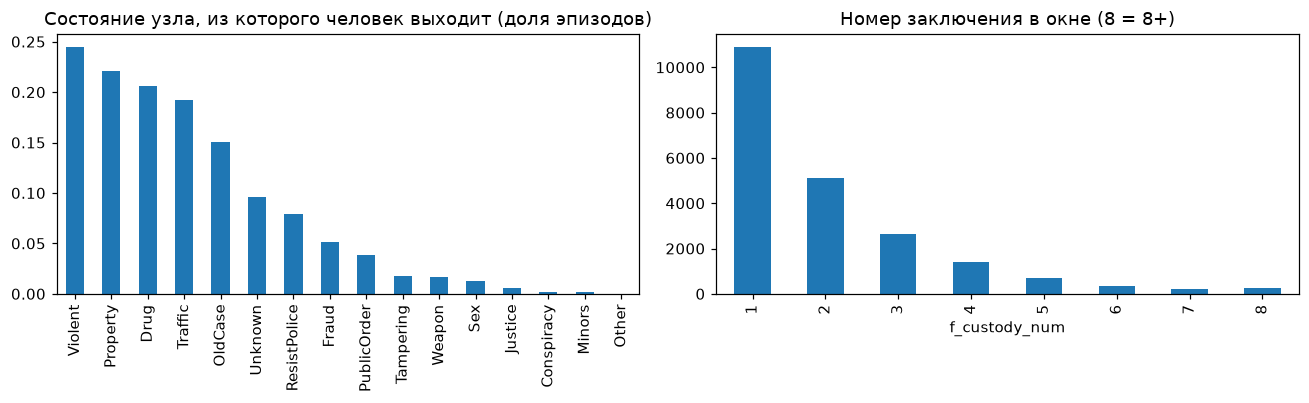

In [10]:
cur = X[[c for c in X.columns if c.startswith('g_cur_') and c[6:7].isupper()]].mean().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
cur.rename(lambda c: c[6:]).plot(kind='bar', ax=ax[0]); ax[0].set_title('Состояние узла, из которого человек выходит (доля эпизодов)')
X.f_custody_num.clip(upper=8).value_counts().sort_index().plot(kind='bar', ax=ax[1]); ax[1].set_title('Номер заключения в окне (8 = 8+)')
plt.tight_layout(); plt.savefig('out/features_overview.png', dpi=120); plt.show()

## Решение 6. Причина возврата: новое дело / старое дело

Возврат в заключение — это и новое преступление, и решение системы по старому делу. Причина берётся из следующего узла графа (поле `reason` — как обвинения привязаны к заключению):

| Причина | `reason` следующего узла | Смысл |
|---|---|---|
| **1 — новое дело** | `new_offense` | арест по делу, по которому у человека ещё не было заключения (в том числе смешанное заключение: новое + старое дело) |
| **2 — старое дело** | `rearrest_old_case` | арест только по делу, по которому у человека уже было заключение в окне (узел `OldCase`) |
| **3 — не определено** | не привязано | нет ареста в [вход − 1 день; вход] и это не перевод (в том числе prison по приговору без ареста при входе) |
| 0 — цензура | — | до 01.04.2016 возврата не было |

Это конкурирующие риски: эпизод заканчивается первым из возвратов, после него второй уже не наблюдается. Причина «не определено» в моделях — отдельное конкурирующее событие, а не цензура.

**Старое дело — по заключениям, а не по арестам.** Дело старое, если по нему у человека уже было заключение в окне 2013+ (prison до 2013 не считается), поэтому возврат по старому делу всегда возвращает человека к делу, которое уже было узлом графа. К узлу `OldCase` привязаны обвинения старого дела с датой не позже входа; отдельными полями записаны номер дела, прошлые заключения по нему, типы его обвинений и число **новых обвинений по старому делу** — появившихся после прошлого заключения (например, нарушение условий освобождения на свободе). Ячейка ниже показывает, сколько таких узлов.

В таблицу записываются `cause` (0–3), `next_reason` и пары `time_new / event_new`, `time_old / event_old`, `time_unknown / event_unknown` (время одно — `time_custody`, событие — возврат по этой причине).

In [11]:
import stage2_extra as sx
fc = sx.add_causes(fe, spells)
cz = fc.cause.map({0: 'цензура', **sx.CAUSE_RU})
tab = pd.DataFrame({'эпизодов': cz.value_counts(), 'доля': cz.value_counts(normalize=True).round(3)})
tab['медиана времени, дн.'] = [fc.time_custody[cz == i].median() for i in tab.index]
display(tab)
pd.crosstab(fc.next_reason.fillna('—'), cz, rownames=['reason следующего узла'], colnames=['причина'])

,эпизодов,доля,"медиана времени, дн."
cause,,,
цензура,10293,0.477,640.0
новое дело,6761,0.313,119.0
старое дело,3427,0.159,132.0
не определено,1116,0.052,156.5


причина,не определено,новое дело,старое дело,цензура
reason следующего узла,,,,
new_offense,0,6761,0,0
rearrest_old_case,0,0,3427,0
не привязано,1116,0,0,0
—,0,0,0,10293


In [12]:
et2 = pd.read_csv(sf.EVENT_TABLE).drop_duplicates('ep_row')
old = et2[et2.old_case_flag]
pd.DataFrame({
    'узлов': [len(et2), len(old), int((old.reason == 'rearrest_old_case').sum()), int((old.reason == 'new_offense').sum()),
              int((old.rearrest_new_charges_n > 0).sum())],
}, index=['все узлы', 'со старым делом', '  только старое дело (OldCase)', '  смешанные (новое + старое дело)',
          '  с новыми обвинениями по старому делу'])

,узлов
все узлы,22646
со старым делом,4963
только старое дело (OldCase),3470
смешанные (новое + старое дело),1493
с новыми обвинениями по старому делу,12


## Решение 7. Раса — семейство G

In [13]:
R, race4 = sx.race_features(fe)
g = pd.DataFrame({'группа': race4, 'person_id': fe.person_id.values, 'прошлых арестов': X.h_n_prior_arrests.values})
g.groupby('группа').agg(эпизодов=('person_id', 'size'), людей=('person_id', 'nunique'), **{'среднее число прошлых арестов': ('прошлых арестов', 'mean')}).round(2)

,эпизодов,людей,среднее число прошлых арестов
группа,,,
AfricanAmerican,11686,5358,7.82
Caucasian,7155,3847,5.05
Hispanic,1586,990,3.65
Other,1170,722,3.72


## Сохранение

`out/free_episodes_features.csv` — одна строка на эпизод на свободе: идентификаторы, цели, причина возврата, признаки семейств A–G. `out/feature_dictionary.csv` — список признаков с семейством. Ноутбуки 02 и 03 читают только этот файл (и кэш узлов / арестов `out/_cache_parts.pkl`).

In [14]:
ds, _ = sf.build_dataset(save=True)
assert len(ds) == len(fe) and np.allclose(ds[X.columns[2:]].values.astype(float), X[X.columns[2:]].values.astype(float), equal_nan=True)
assert (ds.cause.values == fc.cause.values).all() and (ds[R.columns].values == R.values).all()
fam = sf.family_columns(ds)
pd.DataFrame([(k, c) for k, v in fam.items() for c in v], columns=['семейство', 'признак']).to_csv('out/feature_dictionary.csv', index=False)
print('сохранено:', ds.shape, '| людей:', ds.person_id.nunique(), '| доля возвратов в заключение:', round(ds.event_custody.mean(), 3))
print({k: len(v) for k, v in fam.items()}, '| всего признаков:', sum(map(len, fam.values())))

сохранено: (21597, 154) | людей: 10917 | доля возвратов в заключение: 0.523
{'A база': 2, 'B RFM': 6, 'C время': 17, 'D узел графа': 36, 'E история по графу': 28, 'F типы арестов (вся история)': 16, 'F2 обвинения (вся история)': 21, 'G раса': 3} | всего признаков: 129


## Итог

Дальше — ноутбук 02: модели по причинам возврата и сравнение семейств; затем ноутбук 03: дополнения к модели из 02.